# Color-Invariant Saree Design Recognition

### AI Engineer Assessment — AIE-CASE

This notebook demonstrates a computer vision approach for recognizing saree designs even when the color of the saree changes.

## 1. Problem Statement

The same saree design can appear in different color combinations.

A system that relies heavily on color may consider these images to be different designs.

The goal of this project is to recognize the underlying saree design by focusing more on:

- Texture
- Patterns
- Edges
- Local visual structure

The system compares a query saree image with a gallery of saree images and returns the Top 5 most similar designs.

## 2. Project Workflow

The recognition process follows these steps:

```text
Query Saree Image
        |
        v
Image Preprocessing
        |
        v
Grayscale Conversion
        |
        v
Edge Detection + Texture Extraction
        |
        v
Feature Vector
        |
        v
Cosine Similarity
        |
        v
Top 5 Matching Designs

In [1]:
import os
import sys
import cv2
import numpy as np
import matplotlib.pyplot as plt

sys.path.append("../src")

from preprocessing import preprocess_image
from features import extract_features, compare_features
from matcher import find_best_matches

print("Libraries imported successfully!")

Libraries imported successfully!


## 3. Dataset

The project uses 155 saree images collected for the recognition experiment.

The images are stored in the gallery folder. A separate query image is used to test the recognition system.

In [2]:
gallery_folder = "../data/gallery"
query_image = "../data/queries/color_changed.jpg"

gallery_images = [
    file for file in os.listdir(gallery_folder)
    if file.lower().endswith((".jpg", ".jpeg", ".png"))
]

print("Number of gallery images:", len(gallery_images))
print("Query image:", query_image)

Number of gallery images: 155
Query image: ../data/queries/color_changed.jpg


## 4. Query Image

The query image is a color-changed version of a saree image from the gallery.

This allows us to test whether the system can recognize the original design even after its color has been changed.

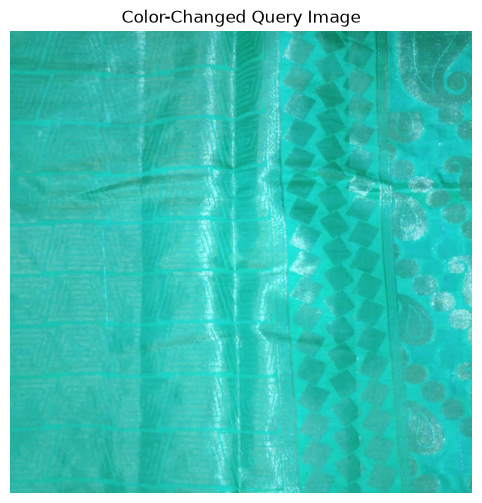

In [3]:
query = cv2.imread(query_image)

query_rgb = cv2.cvtColor(query, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(6, 6))
plt.imshow(query_rgb)
plt.title("Color-Changed Query Image")
plt.axis("off")
plt.show()

## 5. Feature Extraction

The system converts the image into numerical features.

Two important types of information are used:

- **Edges:** capture structural boundaries and patterns.
- **Texture:** captures repeated visual patterns using Local Binary Pattern (LBP).

These features help the system compare saree designs while reducing the effect of color.

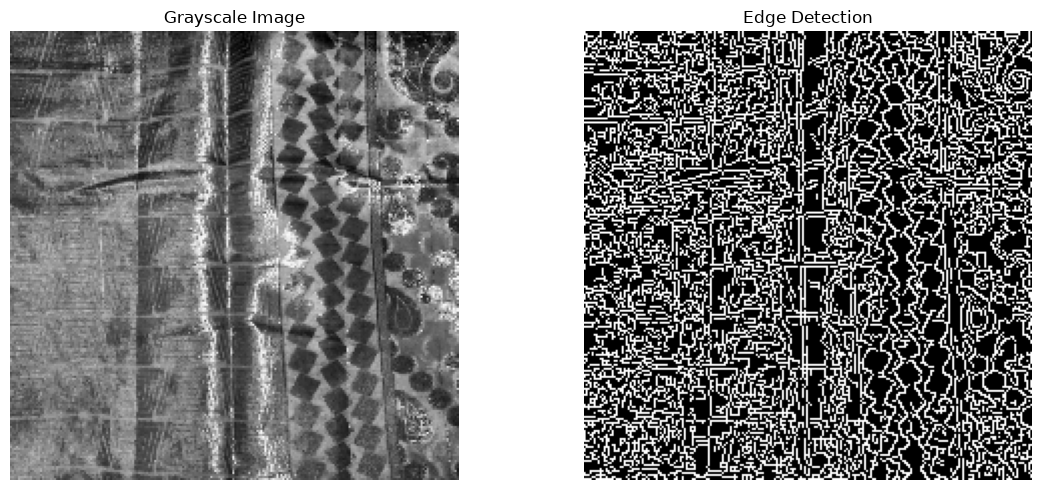

Feature vector size: 4128


In [4]:
enhanced_image, gray_image = preprocess_image(query_image)

features = extract_features(gray_image)

edges = cv2.Canny(
    gray_image,
    40,
    120
)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(gray_image, cmap="gray")
plt.title("Grayscale Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(edges, cmap="gray")
plt.title("Edge Detection")
plt.axis("off")

plt.tight_layout()
plt.show()

print("Feature vector size:", len(features))

## 6. Similarity Matching

The extracted features from the query image are compared with the features of every gallery image.

Cosine similarity is used for comparison.

A higher similarity score means the images have more similar visual patterns and textures.

The system returns the Top 5 matching saree designs.

In [5]:
matches = find_best_matches(
    query_image,
    gallery_folder,
    top_k=5
)

print("Top 5 matching saree designs:\n")

for rank, (filename, similarity) in enumerate(matches, start=1):
    print(
        f"Rank {rank}: {filename} -> "
        f"Similarity: {similarity:.4f}"
    )

Top 5 matching saree designs:

Rank 1: 0001.jpg -> Similarity: 0.9901
Rank 2: 0081.jpg -> Similarity: 0.9720
Rank 3: 0089.jpg -> Similarity: 0.9701
Rank 4: 0079.jpg -> Similarity: 0.9689
Rank 5: 0004.jpg -> Similarity: 0.9677


## 7. Visual Results

The following visualization shows the color-changed query image and the Top 5 designs retrieved by the system.

The original design `0001.jpg` is ranked first with a similarity score of `0.9901`.

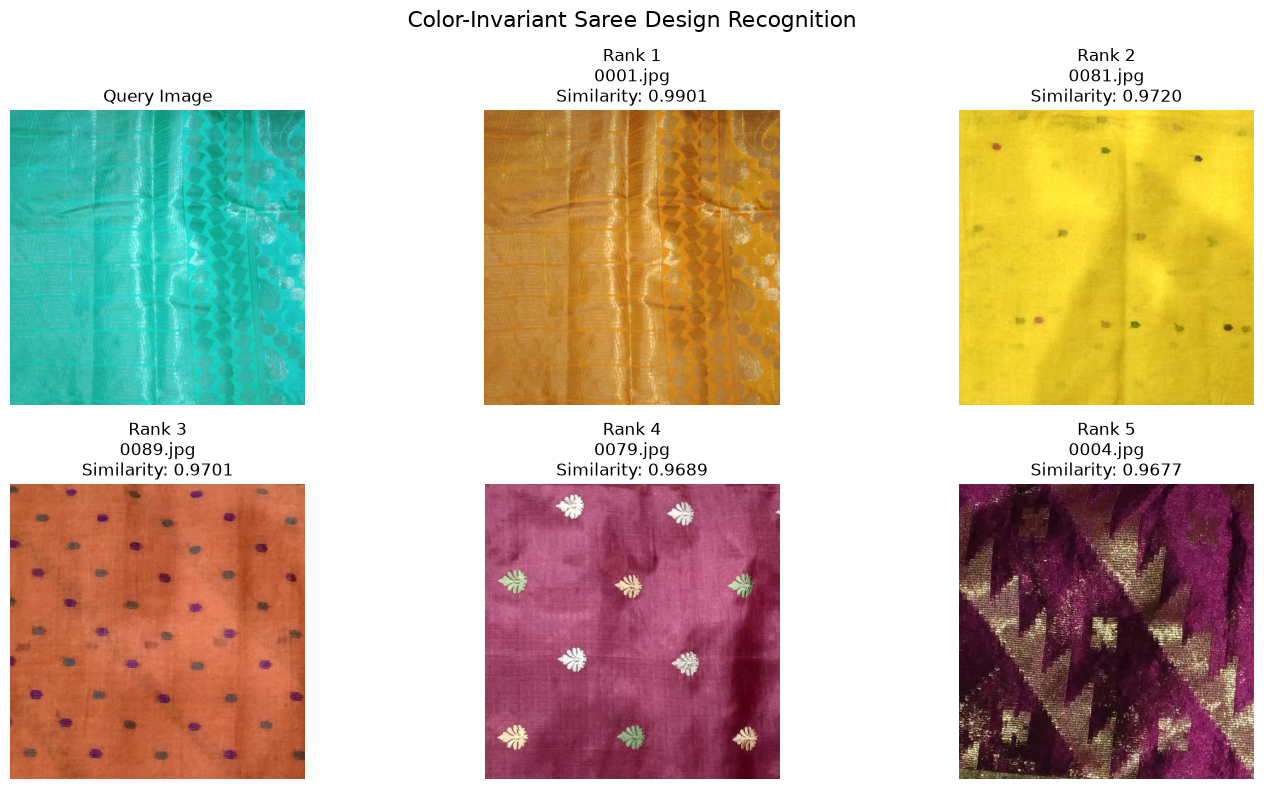

In [6]:
plt.figure(figsize=(15, 8))

# Show query image
query = cv2.imread(query_image)
query = cv2.cvtColor(query, cv2.COLOR_BGR2RGB)

plt.subplot(2, 3, 1)
plt.imshow(query)
plt.title("Query Image")
plt.axis("off")

# Show Top 5 matches
for index, (filename, similarity) in enumerate(matches):

    image_path = os.path.join(
        gallery_folder,
        filename
    )

    image = cv2.imread(image_path)

    if image is None:
        continue

    image = cv2.cvtColor(
        image,
        cv2.COLOR_BGR2RGB
    )

    plt.subplot(2, 3, index + 2)
    plt.imshow(image)

    plt.title(
        f"Rank {index + 1}\n"
        f"{filename}\n"
        f"Similarity: {similarity:.4f}"
    )

    plt.axis("off")

plt.suptitle(
    "Color-Invariant Saree Design Recognition",
    fontsize=16
)

plt.tight_layout()
plt.show()

## 8. Conclusion

The system successfully recognized the original saree design even after changing the color of the query image.

The Top 1 result was `0001.jpg` with a similarity score of `0.9901`.

This demonstrates that texture, edges and local visual structure can help recognize saree designs while reducing the effect of color variation.

## Future Improvements

The project can be further improved by:

- Using deep learning image embeddings
- Adding a larger saree dataset
- Testing more types of color transformations
- Using advanced texture descriptors
- Building a web interface for uploading saree images
- Supporting real-time similarity search